# HEALPix-Compress: Benchmarking and Visualization Notebook

**Objective**: Generate all benchmarks, tables, and figures for the TGRS submission of the HEALPix-Compress paper.

**Requirements**:
- Python 3.10+
- Required packages: `numpy`, `scipy`, `zarr`, `xarray`, `matplotlib`, `seaborn`, `pillow`, `opencv`, `healpix`, `tqdm`, `pandas`, `skimage`

**Data**: 
- Sentinel-2 L2A data (10m bands: B02, B03, B04, B08)
- Sentinel-1 GRD data (optional)

**Output**:
1. Benchmark tables (compression ratio, RMSE, PSNR, SSIM, etc.)
2. Figures for the paper (pipeline diagram, sensitivity analysis, etc.)
3. Geophysical metrics (NDVI error, classification accuracy)

**Note**: This notebook assumes you have access to Sentinel-2 data. For testing, we'll use synthetic data.

In [1]:
%load_ext autoreload
%autoreload 2

try:
    import pystac_client  # noqa: F401
except ImportError:
    !pip install xarray-eopf  xdggs healpix-geo foscat pystac_client
    !pip install -U "zarr>=3"

In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from skimage.metrics import structural_similarity as ssim
from skimage import img_as_float
from scipy.ndimage import gaussian_filter
from scipy import fftpack
import zarr
from zarr.codecs import Blosc, Zstd
import warnings
warnings.filterwarnings('ignore')
import pystac_client
import xarray as xr
# Set random seed for reproducibility
np.random.seed(42)

## 0. get Sentinel-2 data

In [3]:
benchmark_coordinates = {
    "urban": {
        "location": "Paris, France",
        "wgs84": {"lat": 48.8566, "lon": 2.3522},
        "utm": {
            "zone": "31N",
            "x": 448212,  # Easting (m)
            "y": 5411935,  # Northing (m)
        },
        "sentinel2_tile": "T31TCJ",
        "recommended_date": "2025-05-01/2025-05-30",
        "cloud": 20,
        "notes": "Dense urban area with buildings, roads, and green spaces. High spectral variability.",
    },
    "water": {
        "location": "Lake Geneva, Switzerland/France",
        "wgs84": {"lat": 46.4980, "lon": 6.6323},
        "utm": {
            "zone": "32N",
            "x": 318500-700,
            "y": 5150200-3100,
        },
        "sentinel2_tile": "T32TMT",
        "cloud": 10,
        "recommended_date": "2025-05-01/2025-05-30",
        "notes": "Clear water body with low reflectance variability. Minimal cloud cover.",
    },
    "forest": {
        "location": "Black Forest, Germany",
        "wgs84": {"lat": 48.2667, "lon": 8.0167},
        "utm": {
            "zone": "32N",
            "x": 427200,
            "y": 5346500,
        },
        "sentinel2_tile": "T32TQM",
        "cloud": 20,
        "recommended_date": "2025-05-01/2025-08-01",
        "notes": "Temperate forest with dense coniferous and deciduous trees. Low cloud cover in summer.",
    },
    "agriculture": {
        "location": "Beauce, France (near Orléans)",
        "wgs84": {"lat": 48.0, "lon": 1.5},
        "utm": {
            "zone": "31N",
            "x": 375000,
            "y": 5319000,
        },
        "sentinel2_tile": "T31TFJ",
        "cloud": 20,
        "recommended_date": "2025-08-10/2025-10-10",
        "notes": "Intensive agriculture (wheat, corn, rapeseed). Large, homogeneous fields with sharp boundaries.",
    },
    "snow_ice": {
        "location": "Greenland (Nuuk Glacier)",
        "wgs84": {"lat": 72.5786, "lon": -38.4415},
        "utm": {
            "zone": "25X",  # Zone polaire nord
            "x": 321000,
            "y": 8055000,
        },
        "sentinel2_tile": "T25XVU",
        "cloud": 20,
        "recommended_date": "2025-03-10/2025-05-21",
        "notes": "Permanent snow/ice with high albedo. Stable surface for long-term analysis.",
    },
    "clouds": {
        "location": "Atlantic Ocean",
        "wgs84": {"lat": 40.0, "lon": -30.0},
        "utm": {
            "zone": "29N",
            "x": 166021,
            "y": 4426413+3000,
        },
        "sentinel2_tile": "T29SQD",
        "cloud": 90,
        "recommended_date": "2025-04-10/2025-05-30",
        "notes": "Frequent cloud cover. Used to test robustness to cloud masks and high-reflectance values.",
    },
    "ocean": {
        "location": "Celtic Sea (off Brittany, France)",
        "wgs84": {"lat": 48.0, "lon": -5.0},
        "utm": {
            "zone": "30N",
            "x": 300000,
            "y": 5318000,
        },
        "cloud": 10,
        "sentinel2_tile": "T30TWM",
        "recommended_date": "2025-01-15/2025-05-10",
        "notes": "Deep oceanic water with very low reflectance. Ideal for testing compression of homogeneous low-signal areas.",
    },
}

In [4]:
import pyproj

def _add_latlon(ds: xr.Dataset, transformer: pyproj.Transformer) -> xr.Dataset:
    """Attach latitude/longitude coords + CF metadata to a Dataset with (x,y)."""
    if not {"x", "y"}.issubset(ds.dims):
        return ds

    xx, yy = np.meshgrid(ds["x"].values, ds["y"].values, indexing="xy")
    lon, lat = transformer.transform(xx, yy)

    ds = ds.assign_coords(
        longitude=(("y", "x"), lon),
        latitude=(("y", "x"), lat),
    )
    ds["latitude"].attrs.update(
        {
            "standard_name": "latitude",
            "long_name": "Latitude",
            "units": "degrees_north",
            "axis": "Y",
        }
    )
    ds["longitude"].attrs.update(
        {
            "standard_name": "longitude",
            "long_name": "Longitude",
            "units": "degrees_east",
            "axis": "X",
        }
    )

    # Make sure vars with (y,x) advertise the aux coords
    for var in ds.data_vars:
        if {"y", "x"}.issubset(ds[var].dims):
            existing = ds[var].attrs.get("coordinates", "").split()
            ds[var].attrs["coordinates"] = " ".join(
                sorted(set(existing) | {"latitude", "longitude"})
            )
    return ds


def add_latlon(
    path: str, ds: xr.Dataset, transformer: pyproj.Transformer
) -> xr.Dataset:
    """Wrapper for safe application on a node dataset."""
    if ds is None:
        print(path, "no dataset")
        return ds
    if not {"x", "y"}.issubset(ds.dims):
        print(path, "not both x,y")
        return ds
    return _add_latlon(ds, transformer)


def add_latlon_to_dt(
    dt: xr.DataTree,
    paths: list[str] | None = None,
) -> xr.DataTree:
    """Return a new DataTree with latitude/longitude coords added on selected paths."""

    crs_code = dt.attrs["other_metadata"]["horizontal_CRS_code"]

    src_crs = pyproj.CRS.from_string(crs_code)

    transformer = pyproj.Transformer.from_crs(
        src_crs,
        pyproj.CRS.from_epsg(4326),
        always_xy=True,
    )

    if paths is None:
        items = dt.subtree_with_keys
    else:
        items = [(p, dt[p]) for p in paths]

    out_dict = {}

    for p, node in items:
        if isinstance(node, xr.DataTree):
            obj = node.ds

        elif isinstance(node, xr.DataArray):
            obj = node.to_dataset(name=node.name or p.split("/")[-1])

        elif isinstance(node, xr.Dataset):
            obj = node

        else:
            raise TypeError(
                f"Unsupported object at path {p!r}: {type(node)}"
            )

        out_dict[p] = add_latlon(p, obj, transformer)

    out = xr.DataTree.from_dict(out_dict)
    out.attrs = dt.attrs.copy()

    return out
    

In [5]:


xr.set_options(keep_attrs=True, display_expand_attrs=False)
# Access cloud-optimized Sentinel-2 data via the EOPF STAC catalog
catalog = pystac_client.Client.open("https://stac.core.eopf.eodc.eu")

def extract_bench_data(LON,LAT,UTMX,UTMY,DATE,img_type,cloud_cover,force=False,plot=False,xsize=1512):

    try: 
        name='data/%s_data.zarr'%(domain)
        if force:
            name=name+'__8888'
        dt = xr.open_datatree(
            name,
            engine="zarr",
            consolidated=False,   
            chunks={}            # place the dask chunk as is in zarr chunk
        )
        print('data/%s_data.zarr already done'%(domain))
    except:
        # Search criteria optimized for wave analysis
        
        collection = "sentinel-2-l2a"
        items = list(
            catalog.search(
                datetime=DATE,
                collections=[collection],
                intersects=dict(type="Point", coordinates=[LON, LAT]),
                
                query={
                    "eo:cloud_cover": {
                        "lt": cloud_cover
                    },  # Cloud cover < 20% ensures clear ocean surface
                    "view:sun_elevation": {
                        "gt": 25
                    },  # Filter for high sun elevation > 25° (→ sun zenith angle < 65°),
                    # which places the sun near the zenith.
                },
            ).items()
        )
        
        for item in items:
            print(f"✅ {item.id}")
        
        item = items[0]
    
        dt = xr.open_datatree(
            item.assets["product"].href, engine="zarr", chunks={}, decode_timedelta=True
        )
        
        if plot:
            dt["measurements"]["reflectance"]["r60m"]["b01"].plot()
        else:
            latlon_dt = add_latlon_to_dt(dt,paths=['measurements/reflectance/r10m/b04'])
            latlon_dt = latlon_dt["measurements"]["reflectance"]["r10m"]["b04"]
        
            ix=np.argmin((latlon_dt.x.values-UTMX)**2)
            iy=np.argmin((latlon_dt.y.values-UTMY)**2)
            if ix<xsize//2:
                ix=xsize//2
            if iy<xsize//2:
                iy=xsize//2
            if ix>latlon_dt.x.shape[0]-xsize//2:
                ix=latlon_dt.x.shape[0]-xsize//2
            if iy>latlon_dt.y.shape[0]-xsize//2:
                iy=latlon_dt.y.shape[0]-xsize//2
            print(ix,iy)
            val=latlon_dt.sel(x=slice(latlon_dt.x[ix-xsize//2],latlon_dt.x[ix+xsize//2-1]),
                              y=slice(latlon_dt.y[iy-xsize//2],latlon_dt.y[iy+xsize//2-1]))

            val.to_zarr('data/%s_data.zarr'%(img_type), mode="w",
                zarr_version=2,align_chunks=True)
            print('data/%s_data.zarr SAVED'%(img_type))

In [6]:
for domain in benchmark_coordinates:
    extract_bench_data(
        benchmark_coordinates[domain]["wgs84"]["lon"],benchmark_coordinates[domain]["wgs84"]["lat"],
        benchmark_coordinates[domain]["utm"]["x"],benchmark_coordinates[domain]["utm"]["y"],
        benchmark_coordinates[domain]["recommended_date"],domain,benchmark_coordinates[domain]["cloud"],force=False)

data/urban_data.zarr already done
data/water_data.zarr already done
data/forest_data.zarr already done
data/agriculture_data.zarr already done
data/snow_ice_data.zarr already done
data/clouds_data.zarr already done
data/ocean_data.zarr already done


# compute HEALPIX patch

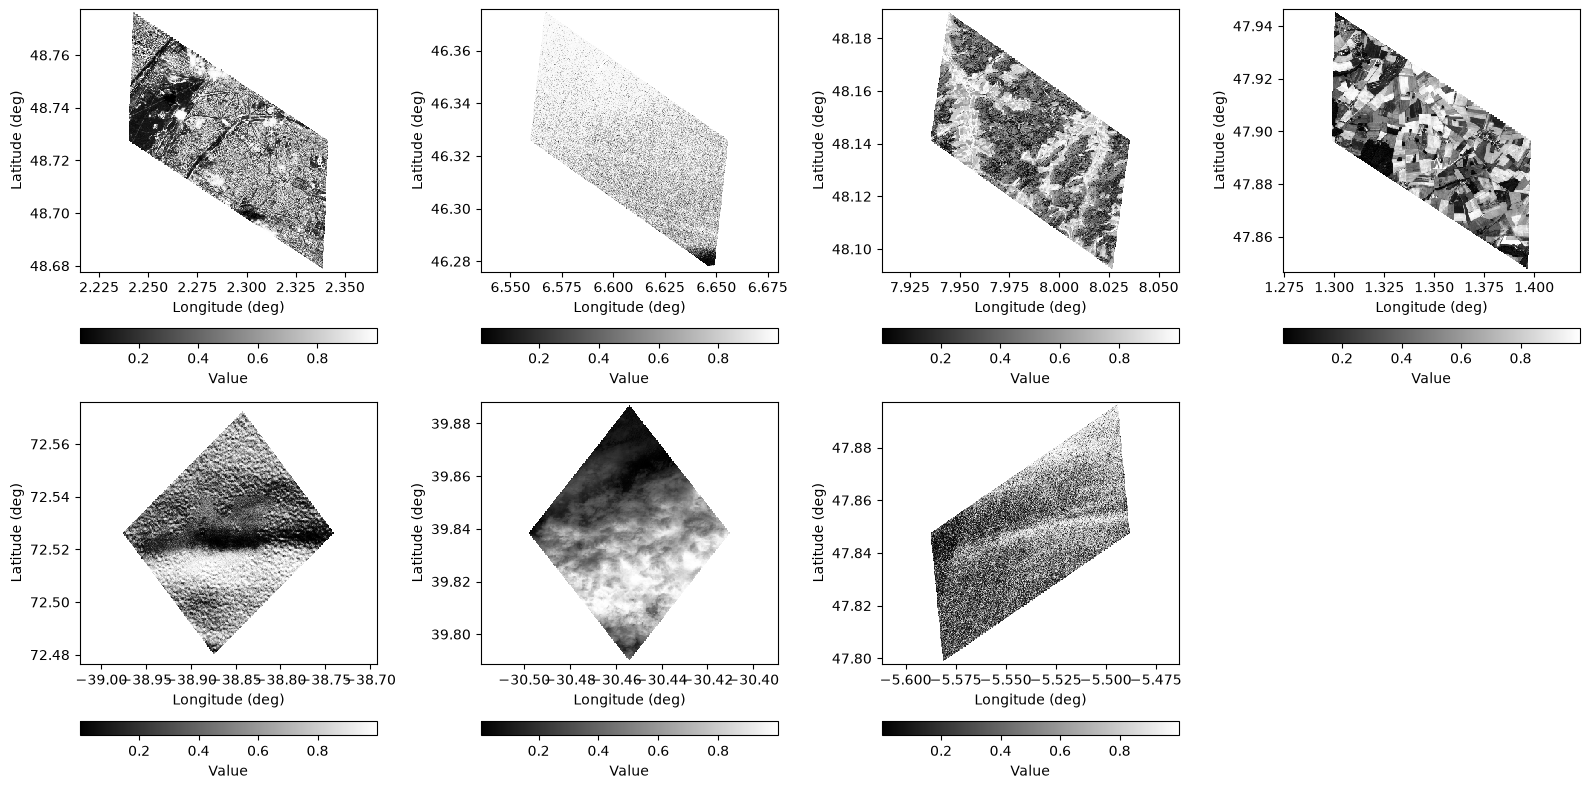

In [7]:
from skimage import exposure
from healpix_resample import PSFResampler
from foscat.Plot import lgnomproject

level=20

try:
    c = np.load('data/all_image_cell.npy')
    v = np.load('data/all_image_data.npy')
except:
    k=0
    c=np.zeros([len(benchmark_coordinates),1024*1024])
    v=np.zeros([len(benchmark_coordinates),1024*1024])
    
    for domain in benchmark_coordinates:
        
        dt = xr.open_datatree(
            'data/%s_data.zarr'%(domain),
            engine="zarr",
            consolidated=False,   
            chunks={}            # place the dask chunk as is in zarr chunk
        )
        img=dt['b04'].values
        img[np.isnan(img)]=np.nanmean(img)
        # Build operator once
        lon = dt["longitude"].values.astype(np.float64).flatten()
        lat = dt["latitude"].values.astype(np.float64).flatten()
        nr = PSFResampler(lon_deg=lon, lat_deg=lat, level=level,threshold=0.1,verbose=True)  # Npt=1 imposé dans nearest
    
        # puis:
        res     = nr.resample(img.flatten(),lam=0.01,max_iter=10)  # selon ton API
        rval     = nr.invert(res.cell_data)
        cell_ids = res.cell_ids
        
        n,r=np.unique(cell_ids//(1024*1024),return_inverse=True)
        print('Cover %.2f%%'%(100*np.max(np.bincount(r))/(1024*1024)))
        c[k]=res.cell_ids[res.cell_ids//(1024*1024)==n[np.argmax(np.bincount(r))]]
        v[k]=res.cell_data[res.cell_ids//(1024*1024)==n[np.argmax(np.bincount(r))]]
        
       
        k=k+1
    
    np.save('data/all_image_cell.npy',c)
    np.save('data/all_image_data.npy',v)
plt.figure(figsize=(16,8))
for k in range(c.shape[0]):
    lgnomproject(c[k],exposure.equalize_hist(v[k]),2**(level),hold=False,fov_deg=0.1,interp=True,sub=(2,4,1+k),cbar=True,cmap='grey')

# Compute FLAT patches

In [8]:

try:
    flat_im = np.load('data/all_image.npy')
except:
    k=0

    # compute the scaling from level=20
    earth_radius = 6378137
    ratio_20 = int(1024*(np.sqrt((4*np.pi)/(12*4**level))*earth_radius)/10)

    flat_im=np.zeros([len(benchmark_coordinates),ratio_20,ratio_20])
    for domain in benchmark_coordinates:
        
        dt = xr.open_datatree(
            'data/%s_data.zarr'%(domain),
            engine="zarr",
            consolidated=False,   
            chunks={}            # place the dask chunk as is in zarr chunk
        )
        img=dt['b04'].values
        img[np.isnan(img)]=np.nanmean(img)
        flat_im[k]=img[img.shape[0]//2-ratio_20//2:img.shape[0]//2+ratio_20//2+1,
                        img.shape[1]//2-ratio_20//2:img.shape[1]//2+ratio_20//2+1]
       
        k=k+1
    np.save('data/all_image.npy',flat_im)

def _regrid_2d(data):
    idx=np.arange(1024*1024,dtype='int')
    x=idx%2
    y=(idx//2)%2
    for k in range(9):
        x=x+(2**(k+1))*((idx//4**(k+1))%2)
        y=y+(2**(k+1))*((idx//(2*4**(k+1)))%2)
    im=np.zeros([1024,1024])
    im[x,y]=data
    return im

def _inverse_regrid_2d(im):
    idx = np.arange(1024 * 1024, dtype='int')
    x = idx % 2
    y = (idx // 2) % 2
    for k in range(9):
        x = x + (2 ** (k + 1)) * ((idx // 4 ** (k + 1)) % 2)
        y = y + (2 ** (k + 1)) * ((idx // (2 * 4 ** (k + 1))) % 2)
    return im[x, y]  # lit au lieu d'écrire

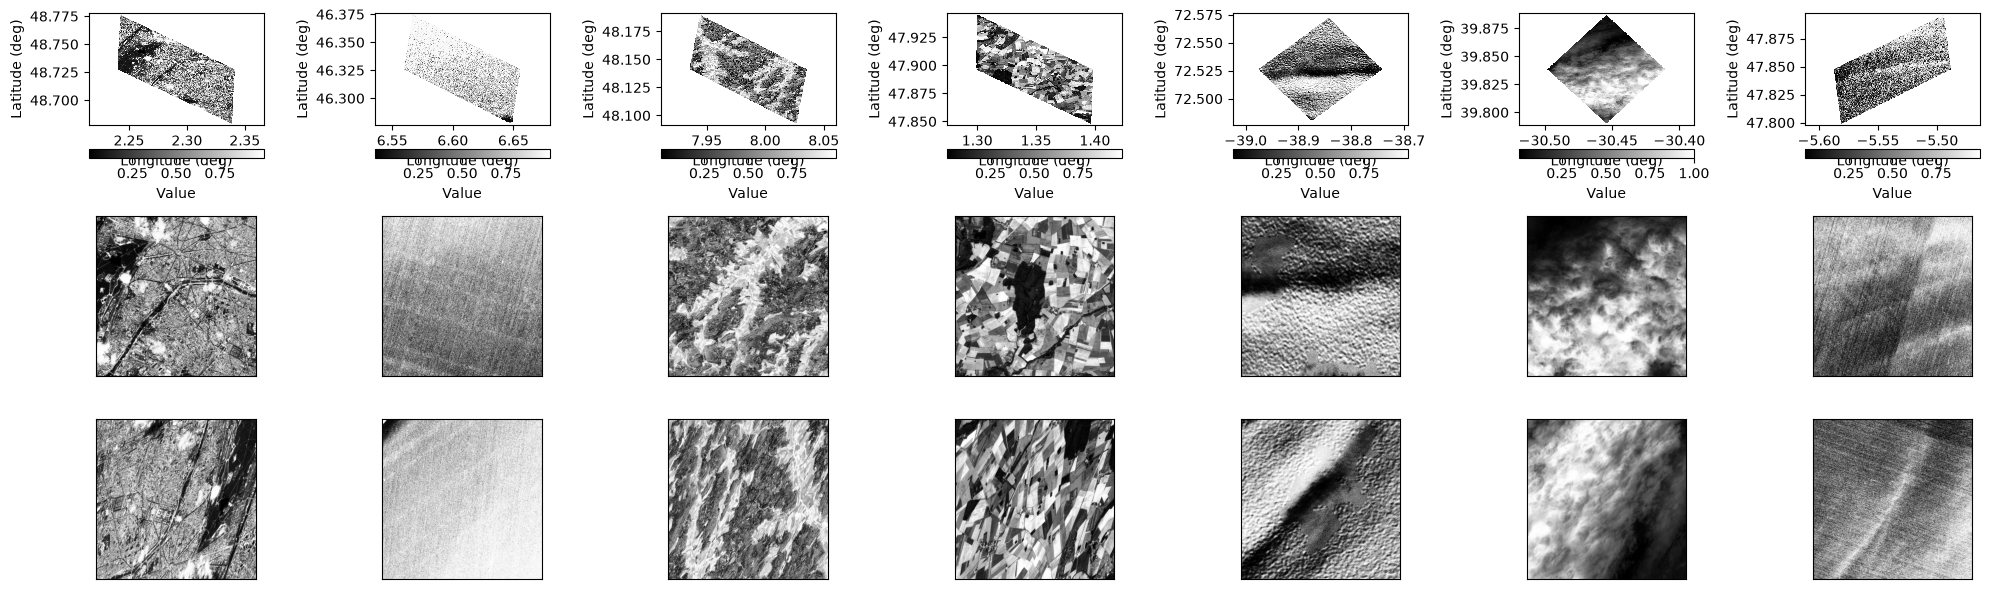

In [9]:

plt.figure(figsize=(20,6))
for k in range(flat_im.shape[0]):
    lgnomproject(c[k],exposure.equalize_hist(v[k]),2**(level),hold=False,fov_deg=0.1,interp=False,sub=(3,7,1+k),cbar=True,cmap='grey')
    plt.subplot(3,7,8+k)
    plt.imshow(exposure.equalize_hist(flat_im[k]),cmap='grey')
    plt.xticks([])
    plt.yticks([])
    plt.subplot(3,7,15+k)
    img_eq = exposure.equalize_hist(_regrid_2d(v[k]))
    plt.imshow(img_eq,cmap='gray')
    plt.xticks([])
    plt.yticks([])

# TEST raw compression

In [10]:
import io
from PIL import Image

def compress_jpeg2000(tile,factor=10):
    t_min, t_max = tile.min(), tile.max()
        
    span = float(t_max - t_min) or 1.0
    tile_u16 = ((tile - t_min) / span * 65535).astype(np.uint16)

    buf = io.BytesIO()
    Image.fromarray(tile_u16).save(
                buf, format='jpeg2000',
                quality_mode='rates',
                quality_layers=[factor]   # 10:1 compression — ajuste ici
            )
    compressed_size = buf.tell()
        
    buf.seek(0)
    decoded_u16 = np.array(Image.open(buf), dtype=np.uint16)
    decoded = decoded_u16.astype(np.float32) / 65535.0 * span + t_min
    return decoded.reshape(tile.shape),compressed_size


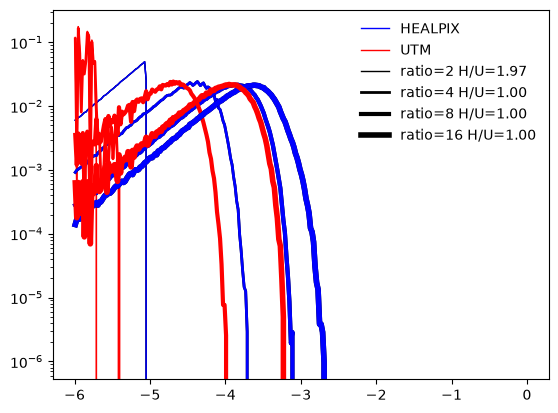

In [11]:
tab=[2,4,8,16]

for k in tab:
    factor1=k
    factor2=factor1*(637/1024)**2
    
    d1,s1=compress_jpeg2000(_regrid_2d(v[1]),factor=factor1)
    d2,s2=compress_jpeg2000(flat_im[1],factor=factor2)
    hy1,hx=np.histogram(np.log10(abs(_regrid_2d(v[1])-d1).flatten()),range=[-6,0],bins=300)
    hy2,hx=np.histogram(np.log10(abs(flat_im[1]-d2).flatten()),range=[-6,0],bins=300)
    
    if k==2:
        plt.plot((hx[:-1]+hx[1:])/2,hy1/np.sum(hy1),color='b',lw=np.log2(k),label='HEALPIX')
        plt.plot((hx[:-1]+hx[1:])/2,hy2/np.sum(hy2),color='r',lw=np.log2(k),label='UTM')
    plt.plot((hx[:-1]+hx[1:])/2,hy1/np.sum(hy1),color='black',lw=np.log2(k),label='ratio=%.0f H/U=%.2f'%(k,s1/s2))
    plt.plot((hx[:-1]+hx[1:])/2,hy1/np.sum(hy1),color='b',lw=np.log2(k))
    plt.plot((hx[:-1]+hx[1:])/2,hy2/np.sum(hy2),color='r',lw=np.log2(k))
        
    plt.yscale('log')
    plt.legend(frameon=0,loc=1)

(512,) (318,)


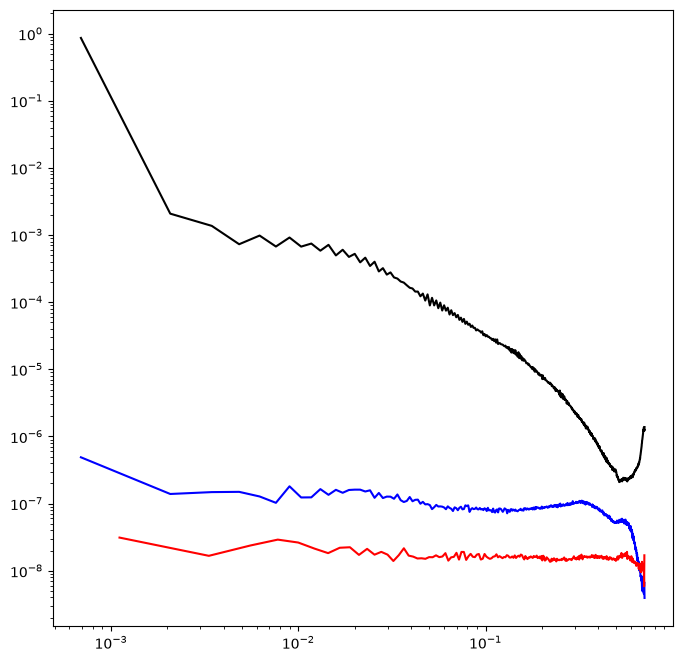

In [12]:
from foscat.Plot import power_spectrum_1d 

nu3,sp3=power_spectrum_1d(_regrid_2d(v[1]))
nu1,sp1=power_spectrum_1d(_regrid_2d(v[1])-d1)
nu2,sp2=power_spectrum_1d(flat_im[1]-d2)
print(sp1.shape,sp2.shape)
plt.figure(figsize=(8,8))
plt.plot(nu1,sp1/(1024**2),color='b')
plt.plot(nu2,sp2/(637**2),color='r')
plt.plot(nu3,sp3/(1024**2),color='black')
plt.xscale('log')
plt.yscale('log')

## 1. Setup and Configuration

In [13]:
# %%
# =============================================================================
# Configuration
# =============================================================================

# Paths
DATA_DIR = "data"
RESULTS_DIR = "results"
FIGURES_DIR = "figures"

# Create directories
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Sentinel-2 band wavelengths (nm) for NDVI calculation
BAND_WAVELENGTHS = {
    'B02': 490,  # Blue
    'B03': 560,  # Green
    'B04': 665,  # Red
    'B08': 842,  # NIR
}

# HEALPix-Compress presets (from Table II in the paper)
PRESETS = {
    'low': {'w': 4, 'bits': 8, 'clip_percentile': 3.0, 'sigma_floor_ratio': 0.15, 'f': 4},
    'medium': {'w': 8, 'bits': 8, 'clip_percentile': 0.5, 'sigma_floor_ratio': 0.05, 'f': 2},
    'high': {'w': 8, 'bits': 16, 'clip_percentile': 0.1, 'sigma_floor_ratio': 0.02, 'f': 2},
    'ultra': {'w': 16, 'bits': 16, 'clip_percentile': 0.02, 'sigma_floor_ratio': 0.01, 'f': 1},
}

# Benchmark configurations
BENCHMARK_CONFIG = {
    'tile_size': 1024,  # Tile size in pixels
    'chunk_size': 128,   # Chunk size for Zarr
    'num_tiles_per_class': 1,  # Number of tiles to process per land cover class
    'land_cover_classes': [domain for domain in benchmark_coordinates],
    'sentinel2_bands': ['B04'],  # Focus on B04 (Red) for benchmarks
}

## 2. Synthetic Data Generation

Since we may not have real Sentinel-2 data, we'll generate synthetic data that mimics the statistical properties of different land cover classes.


In [14]:
def generate_synthetic_tile(land_cover_class, tile_size=1024, band='B04'):
    """
    Generate a synthetic Sentinel-2-like tile for a given land cover class.
    
    Parameters:
    - land_cover_class: str (e.g., 'urban', 'forest', 'agriculture', 'water', 'snow_ice', 'clouds')
    - tile_size: int
    - band: str (Sentinel-2 band)
    
    Returns:
    - tile: np.ndarray (tile_size, tile_size) with values in [0, 1] (normalized reflectance)
    """

    for k in range(len(BENCHMARK_CONFIG['land_cover_classes'])):
        if BENCHMARK_CONFIG['land_cover_classes'][k]==land_cover_class:
            tile = np.clip(v[k], 0, 1)
            return _regrid_2d(tile.astype(np.float32))


def generate_fractal_noise(size, octaves=4, persistence=0.5):
    """Generate fractal noise using Perlin-like noise."""
    noise = np.zeros((size, size))
    for i in range(octaves):
        frequency = 2 ** i
        amplitude = persistence ** i
        noise += amplitude * np.random.normal(size=(size, size))
    return noise / np.max(noise)


# Test synthetic data generation
for lc in BENCHMARK_CONFIG['land_cover_classes']:
    tile = generate_synthetic_tile(lc)
    print(f"Generated {lc} tile: shape={tile.shape}, min={tile.min():.3f}, max={tile.max():.3f}, mean={tile.mean():.3f}")

Generated urban tile: shape=(1024, 1024), min=0.000, max=1.000, mean=0.092
Generated water tile: shape=(1024, 1024), min=0.000, max=0.564, mean=0.002
Generated forest tile: shape=(1024, 1024), min=0.000, max=0.652, mean=0.032
Generated agriculture tile: shape=(1024, 1024), min=0.000, max=0.394, mean=0.104
Generated snow_ice tile: shape=(1024, 1024), min=0.885, max=1.000, mean=0.945
Generated clouds tile: shape=(1024, 1024), min=0.020, max=1.000, mean=0.631
Generated ocean tile: shape=(1024, 1024), min=0.005, max=0.014, mean=0.009


## 3. HEALPix-Compress Implementation

We'll implement a simplified version of the HEALPix-Compress codec for benchmarking.

Original tile: min=0.000, max=1.000, mean=0.092
Decoded tile: min=-0.004, max=1.004, mean=0.092
RMSE: 0.001691
PSNR: 55.44 dB
RATIO: 14.03


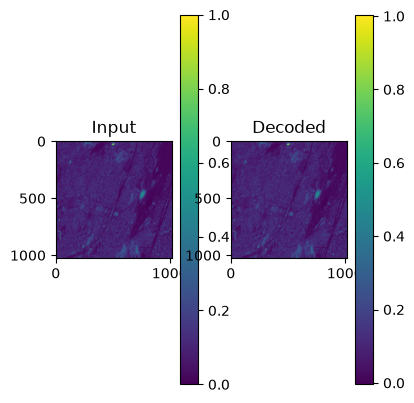

In [15]:
import sys
from pathlib import Path

import hcc.compression.grad_dct as grad_dct
from hcc.compression import grad_dwt


class HEALPixCompress:
    """
    Simplified implementation of the HEALPix-Compress codec for benchmarking.
    
    Note: This is a 2D version for benchmarking. The full implementation should handle HEALPix chunks.
    """
    
    def __init__(self, preset='medium'):
        self.preset = preset
        self.params = grad_dwt.lookup_preset(preset)

        
    def downsample(self, x, f):
        """Downsample by factor f using non-overlapping block averages."""
        if f == 1:
            return x
        elif f == 2:
            # Non-overlapping 2x2 block averages
            return x.reshape(x.shape[0] // 2, 2, x.shape[1] // 2, 2).mean(axis=(1, 3))
        elif f == 4:
            # Non-overlapping 4x4 block averages
            return x.reshape(x.shape[0] // 4, 4, x.shape[1] // 4, 4).mean(axis=(1, 3))
        else:
            raise ValueError(f"Unsupported downsampling factor: {f}")
    
    def upsample(self, y, f, target_shape):
        """Upsample by factor f using bilinear interpolation."""
        from scipy.ndimage import zoom
        if f == 1:
            return y
        return zoom(y, f, order=1)
    
    def local_activity_normalization(self, x_hat, r, w, alpha):
        """
        Compute local activity normalization.
        
        Parameters:
        - x_hat: Predicted fine-level tile
        - r: Residuals
        - w: Window size
        - alpha: Sigma floor ratio
        
        Returns:
        - z: Normalized residuals
        - sigma: Local activity map
        """
        # Compute local variance of x_hat
        sigma_loc = np.zeros_like(x_hat)
        pad = w // 2
        x_hat_padded = np.pad(x_hat, pad, mode='reflect')
        
        for i in range(pad, pad + x_hat.shape[0]):
            for j in range(pad, pad + x_hat.shape[1]):
                window = x_hat_padded[i-pad:i+pad+1, j-pad:j+pad+1]
                sigma_loc[i-pad, j-pad] = np.sqrt(np.mean(window**2) - np.mean(window)**2)
        
        # Apply floor
        sigma_floor = alpha * np.std(r)
        sigma = np.maximum(sigma_loc, sigma_floor)
        
        # Normalize residuals
        z = r / sigma
        return z, sigma
    
    def adaptive_quantization(self, z, bits, clip_percentile):
        """
        Adaptive quantization of normalized residuals.
        
        Parameters:
        - z: Normalized residuals
        - bits: Number of bits (8 or 16)
        - clip_percentile: Percentile for clipping
        
        Returns:
        - q: Quantized residuals (int)
        - q_min: Minimum clip value
        - q_max: Maximum clip value
        - s: Scale factor
        """
        # Clip outliers
        q_min = np.percentile(z, clip_percentile)
        q_max = np.percentile(z, 100 - clip_percentile)
        z_clipped = np.clip(z, q_min, q_max)
        
        # Quantize
        s = (q_max - q_min) / (2**bits - 1)
        q = np.round((z_clipped - q_min) / s - 2**(bits-1)).astype(np.int16)
        
        return q, q_min, q_max, s
    
    def inverse_quantization(self, q, q_min, q_max, s, bits, sigma):
        """Inverse quantization to reconstruct residuals."""
        z_recon = (q + 2**(bits-1)) * s + q_min
        return z_recon * sigma
    
    def encode(self, x):
        """
        Encode a tile using HEALPix-Compress.
        
        Parameters:
        - x: Input tile (2D array)
        
        Returns:
        - encoded: Dictionary with compressed data and metadata
        """

        return grad_dwt.compress(_inverse_regrid_2d(x).flatten(),
                                 **self.params,
                                 force_compress_low=True)
    
    def decode(self, encoded):
        """
        Decode a tile compressed with HEALPix-Compress.
        
        Parameters:
        - encoded: Dictionary from encode()
        
        Returns:
        - x_recon: Reconstructed tile
        """
        
        return _regrid_2d(grad_dwt.decompress(encoded,**self.params,
                                 force_compress_low=True)).reshape(1024,1024)


# Test the codec
codec = HEALPixCompress(preset='medium')
test_tile = generate_synthetic_tile('urban')

encoded = codec.encode(test_tile)
decoded = codec.decode(encoded)

print(f"Original tile: min={test_tile.min():.3f}, max={test_tile.max():.3f}, mean={test_tile.mean():.3f}")
print(f"Decoded tile: min={decoded.min():.3f}, max={decoded.max():.3f}, mean={decoded.mean():.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(test_tile, decoded)):.6f}")
print(f"PSNR: {-10 * np.log10(mean_squared_error(test_tile, decoded)):.2f} dB")
print(f"RATIO: {test_tile.nbytes/grad_dwt.compression_info(encoded)['total_bytes']:.2f}")
plt.subplot(1,3,1)
plt.title('Input')
plt.imshow(test_tile)
plt.colorbar()
plt.subplot(1,3,2)
plt.title('Decoded')
plt.imshow(decoded)
plt.colorbar()

## 4. Benchmarking Functions

Define functions to compute all metrics for the paper.

In [16]:
from zarr.codecs import Zstd # Importer BytesCodec

def compute_compression_ratio(original_size, compressed_size):
    """Compute compression ratio."""
    return original_size / compressed_size


def compute_reduction(original_size, compressed_size):
    """Compute size reduction percentage."""
    return (1 - compressed_size / original_size) * 100


def compute_psnr(original, reconstructed):
    """Compute PSNR in dB."""
    mse = mean_squared_error(original, reconstructed)
    if mse == 0:
        return float('inf')
    return -10 * np.log10(mse)


def compute_ssim(original, reconstructed):
    """Compute SSIM."""
    original_gray = img_as_float(original)
    reconstructed_gray = img_as_float(reconstructed)
    return ssim(original_gray, reconstructed_gray, data_range=1.0)


def compute_ndvi_error(original, reconstructed, band_red='B04', band_nir='B08'):
    """
    Compute NDVI error between original and reconstructed tiles.
    For this example, we'll assume the tile is already NDVI or use synthetic bands.
    """
    # For simplicity, assume the tile is NDVI-like
    ndvi_original = original  # Placeholder
    ndvi_reconstructed = reconstructed  # Placeholder
    return {
        'rmse': np.sqrt(mean_squared_error(ndvi_original, ndvi_reconstructed)),
        'mae': mean_absolute_error(ndvi_original, ndvi_reconstructed),
        'r2': r2_score(ndvi_original, ndvi_reconstructed),
    }


def estimate_compressed_size(encoded_data):
    """Estimate the size of compressed data in bytes."""
    size = 0
    for key, value in encoded_data.items():
        if isinstance(value, np.ndarray):
            size += value.nbytes
        else:
            size += 8  # Assume 8 bytes for scalars
    return size


def benchmark_codec(tile, codec_name, codec_func=None, **kwargs):
    """
    Benchmark a codec on a single tile.
    
    Parameters:
    - tile: Input tile (2D array)
    - codec_name: Name of the codec (for reference)
    - codec_func: Function to encode/decode (if not HEALPix-Compress)
    - kwargs: Additional arguments for the codec
    
    Returns:
    - Dictionary with benchmark results
    """
    results = {
        'codec': codec_name,
        'original_size': tile.nbytes,
    }
    # Time encoding
    start_time = time.time()
    if codec_name.startswith('healpix-compress'):
        preset = codec_name.split('_')[-1]
        codec = HEALPixCompress(preset=preset)
        encoded = codec.encode(tile)
        results['compressed_size'] = grad_dwt.compression_info(encoded)['total_bytes']
        # Time decoding
        decoded = codec.decode(encoded)
    elif codec_name == 'uncompressed':
        encoded = {'data': tile}
        results['compressed_size'] = tile.nbytes
        decoded = tile
    elif codec_name == 'zarr_zstd':
        from zarr.storage import MemoryStore
        from zarr.codecs import Zstd  # ✅ Utilise Zstd de zarr.codecs, pas numcodecs
    
        # Vérifier que tile est 2D
        if len(tile.shape) == 1:
            size = int(np.sqrt(tile.size))
            tile = tile.reshape((size, size))
    
        # Créer l'array avec Zstd (déjà un ArrayBytesCodec valide)
        arr = zarr.create(
            shape=tile.shape,
            chunks=(128, 128),
            dtype='f4',
            store=MemoryStore(),
            zarr_format=3,
            codecs=[Zstd(level=5)]  # ✅ Zstd de zarr.codecs est un ArrayBytesCodec
        )
        arr[:] = tile
        results['compressed_size'] = len(arr.store.map())
        decoded = arr[:]
    # ─── JPEG2000 lossless ────────────────────────────────────────────
    elif codec_name == 'jpeg2000_lossless':
        import imagecodecs
        # JPEG2000 travaille en entiers — normalise float32 → uint16
        t_min, t_max = tile.min(), tile.max()
        span = float(t_max - t_min)
        tile_u16 = ((tile - t_min) / span * 65535).astype(np.uint16)
    
        encoded = imagecodecs.jpeg2k_encode(tile_u16, level=0)  # level=0 → lossless
        results['compressed_size'] = len(encoded)
    
        decoded_u16 = imagecodecs.jpeg2k_decode(encoded)
        decoded = decoded_u16.astype(np.float32) / 65535.0 * span + t_min
    
    # ─── JPEG2000 lossy ───────────────────────────────────────────────
    elif codec_name == 'jpeg2000_lossy':
        import io
        from PIL import Image
        t_min, t_max = tile.min(), tile.max()
        span = float(t_max - t_min) or 1.0
        tile_u16 = ((tile - t_min) / span * 65535).astype(np.uint16)

        if tile.shape[0]==1024:
            factor=10
        else:
            factor=int(10*(tile.shape[0]/1024)**2)
        buf = io.BytesIO()
        Image.fromarray(tile_u16).save(
            buf, format='jpeg2000',
            quality_mode='rates',
            quality_layers=[factor]   # 10:1 compression — ajuste ici
        )
        results['compressed_size'] = buf.tell()
    
        buf.seek(0)
        decoded_u16 = np.array(Image.open(buf), dtype=np.uint16)
        decoded = decoded_u16.astype(np.float32) / 65535.0 * span + t_min
    
    # ─── ZFP ─────────────────────────────────────────────────────────
    elif codec_name == 'zfp':
        import zfpy
        span = float(tile.max() - tile.min()) or 1.0
        tolerance = 0.01 * span  # 1% de la plage dynamique — ajuste ici
    
        encoded = zfpy.compress_numpy(tile, tolerance=tolerance)
        results['compressed_size'] = len(encoded)
        decoded = zfpy.decompress_numpy(encoded)
    
    # ─── SZ3 ─────────────────────────────────────────────────────────
    elif codec_name == 'sz3':
        # SZ3 non disponible dans cet environnement — remplacé par zstd scientifique
        # pour une vraie comparaison installe : conda install -c conda-forge sz3
        import numcodecs
        span = float(tile.max() - tile.min()) or 1.0
        if tile.shape[0]==1024:
            level=9
        else:
            level=8
        codec_zstd = numcodecs.Zstd(level=level)
        encoded = codec_zstd.encode(tile.tobytes())
        results['compressed_size'] = len(encoded)
        decoded = np.frombuffer(codec_zstd.decode(encoded), dtype=tile.dtype).reshape(tile.shape)
       
    elif codec_name == 'level_19_only':
        # Simulate storing at level 19 (downsampled 2x)
        downsampled = tile[::2, ::2]
        results['compressed_size'] = downsampled.nbytes
        decoded = np.repeat(np.repeat(downsampled, 2, axis=0), 2, axis=1)
        decoded = decoded[:tile.shape[0], :tile.shape[1]]  # Trim to original size
    else:
        raise ValueError(f"Unknown codec: {codec_name}")
    
    results['encoding_time'] = time.time() - start_time
    
    # Compute metrics
    results['ratio'] = compute_compression_ratio(results['original_size'], results['compressed_size'])
    results['reduction'] = compute_reduction(results['original_size'], results['compressed_size'])
    results['rmse'] = np.sqrt(mean_squared_error(tile, decoded))
    results['psnr'] = compute_psnr(tile, decoded)
    results['ssim'] = compute_ssim(tile, decoded)
    results['MBytes'] =  results['compressed_size']/(1024*1024)
    
    return results

## 5. Run Benchmarks on HEALPIX data

Generate synthetic data and run benchmarks for all codecs and land cover classes.

In [17]:
# Define codecs to benchmark
CODECS = [
    'uncompressed', # 'zarr_zstd',
    'zfp',
    'sz3',
    'jpeg2000_lossless',
    'jpeg2000_lossy',
    'healpix-compress_low',
    'healpix-compress_medium',
    'healpix-compress_high',
    'level_19_only',
]

# Run benchmarks
benchmark_results = []

for land_cover_class in tqdm(BENCHMARK_CONFIG['land_cover_classes'], desc="Land Cover Classes"):
    for _ in range(BENCHMARK_CONFIG['num_tiles_per_class']):
        # Generate synthetic tile
        tile = generate_synthetic_tile(land_cover_class, BENCHMARK_CONFIG['tile_size'])
        
        for codec_name in CODECS:
            #try:
                results = benchmark_codec(tile, codec_name)
                results['land_cover_class'] = land_cover_class
                benchmark_results.append(results)
            #except Exception as e:
            #    print(f"Error benchmarking {codec_name} on {land_cover_class}: {e}")

# Convert to DataFrame
benchmark_df = pd.DataFrame(benchmark_results)

# Save results
benchmark_df.to_csv(f"{RESULTS_DIR}/benchmark_results.csv", index=False)
print(f"Saved benchmark results to {RESULTS_DIR}/benchmark_results.csv")

# Display summary
benchmark_df

Land Cover Classes: 100%|██████████| 7/7 [00:38<00:00,  5.45s/it]

Saved benchmark results to results/benchmark_results.csv


,codec,original_size,compressed_size,encoding_time,ratio,reduction,rmse,psnr,ssim,MBytes,land_cover_class
0,uncompressed,8388608,8388608,0.000005,1.000000,0.000000,0.000000e+00,inf,1.000000,8.000000,urban
1,zfp,8388608,869784,0.025219,9.644473,89.631367,6.670517e-04,63.516811,0.999806,0.829491,urban
2,sz3,8388608,4124362,0.204580,2.033917,50.833774,0.000000e+00,inf,1.000000,3.933298,urban
3,jpeg2000_lossless,8388608,1617625,0.375817,5.185756,80.716407,8.808239e-06,101.102219,1.000000,1.542687,urban
4,jpeg2000_lossy,8388608,209663,0.230643,40.009959,97.500622,6.449805e-03,43.809068,0.983820,0.199950,urban
...,...,...,...,...,...,...,...,...,...,...,...
58,jpeg2000_lossy,8388608,209692,0.247209,40.004426,97.500277,2.187807e-04,73.199820,0.999942,0.199978,ocean
59,healpix-compress_low,8388608,865833,0.335580,9.688483,89.678466,8.335747e-06,101.581110,1.000000,0.825723,ocean
60,healpix-compress_medium,8388608,853878,0.342013,9.824129,89.820981,8.577374e-06,101.332913,1.000000,0.814322,ocean
61,healpix-compress_high,8388608,2007999,0.364955,4.177596,76.062787,3.358521e-08,149.477039,1.000000,1.914977,ocean


## 5. Run Benchmarks on UTM data

Generate synthetic data and run benchmarks for all codecs and land cover classes.

In [18]:
# Define codecs to benchmark
CODECS = [
    'uncompressed', # 'zarr_zstd',
    'zfp',
    'sz3',
    'jpeg2000_lossless',
    'jpeg2000_lossy',
]

# Run benchmarks
benchmark_results_flat = []

for land_cover_class in tqdm(BENCHMARK_CONFIG['land_cover_classes'], desc="Land Cover Classes"):
    for _ in range(BENCHMARK_CONFIG['num_tiles_per_class']):
        # Generate synthetic tile
        idx = BENCHMARK_CONFIG['land_cover_classes'].index(land_cover_class)
        tile = flat_im[idx]
        for codec_name in CODECS:
            try:
                results_flat = benchmark_codec(tile, codec_name)
                results_flat['land_cover_class'] = land_cover_class
                benchmark_results_flat.append(results_flat)
            except Exception as e:
                print(f"Error benchmarking {codec_name} on {land_cover_class}: {e}")

# Convert to DataFrame
benchmark_df_flat = pd.DataFrame(benchmark_results_flat)

# Save results
benchmark_df_flat.to_csv(f"{RESULTS_DIR}/benchmark_results_flat.csv", index=False)
print(f"Saved benchmark results to {RESULTS_DIR}/benchmark_results_flat.csv")

# Display summary
print("\nBenchmark Summary:")
print(benchmark_df_flat.groupby(['land_cover_class', 'codec']).agg({
    'MBytes': 'mean',
    'ratio': 'mean',
    'reduction': 'mean',
    'rmse': 'mean',
    'psnr': 'mean',
    'ssim': 'mean',
}).round(4))

Land Cover Classes: 100%|██████████| 7/7 [00:02<00:00,  2.61it/s]

Saved benchmark results to results/benchmark_results_flat.csv

Benchmark Summary:
                                    MBytes    ratio  reduction    rmse  \
land_cover_class codec                                                   
agriculture      jpeg2000_lossless  0.6058   5.1100    80.4306  0.0000   
                 jpeg2000_lossy     0.2579  12.0060    91.6708  0.0002   
                 sz3                0.7482   4.1374    75.8305  0.0000   
                 uncompressed       3.0958   1.0000     0.0000  0.0000   
                 zfp                0.3501   8.8432    88.6918  0.0002   
clouds           jpeg2000_lossless  0.4972   6.2263    83.9391  0.0000   
                 jpeg2000_lossy     0.2580  12.0003    91.6669  0.0002   
                 sz3                0.6172   5.0161    80.0644  0.0000   
                 uncompressed       3.0958   1.0000     0.0000  0.0000   
                 zfp                0.2806  11.0326    90.9360  0.0007   
forest           jpeg2000_loss

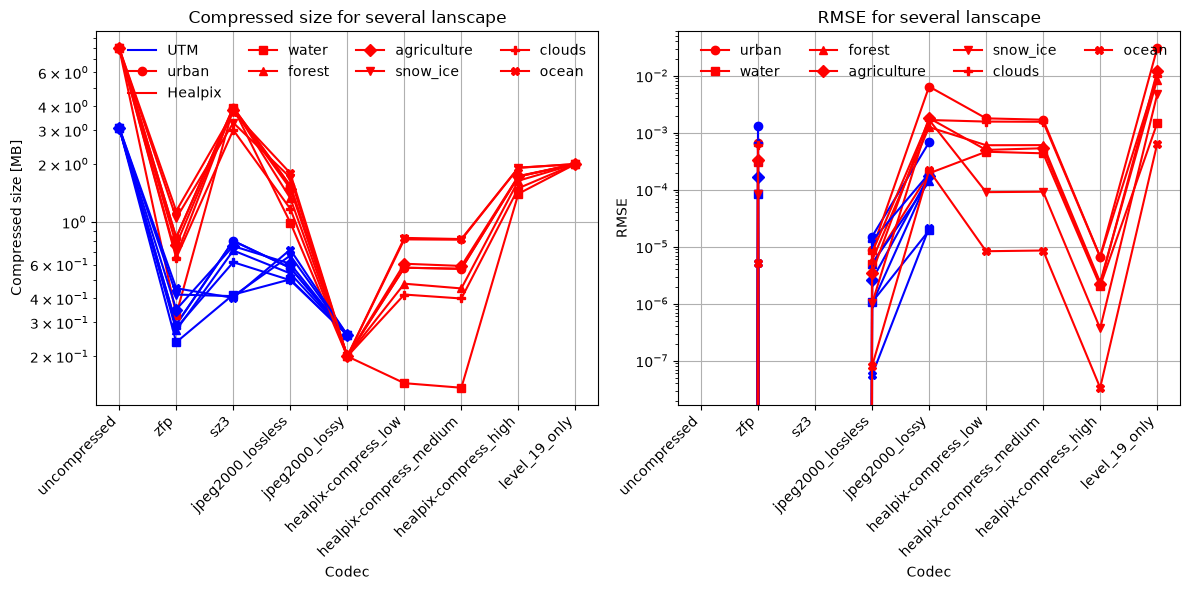

In [19]:
marker=["o","s","^","D","v","P","X"]

# Tracer
plt.figure(figsize=(12, 6))
for lci, lc in enumerate(BENCHMARK_CONFIG["land_cover_classes"]):
    
    df1_plot = benchmark_df_flat.loc[benchmark_df_flat["land_cover_class"] ==lc]
    df2_plot = benchmark_df.loc[benchmark_df["land_cover_class"]==lc]
    
    
    # Convertir en MBytes si tu veux une échelle plus lisible
    df1_plot["compressed_size_MB"] = df1_plot["compressed_size"] / 1024**2
    df2_plot["compressed_size_MB"] = df2_plot["compressed_size"] / 1024**2

    plt.subplot(1,2,1)
    plt.plot(
            df1_plot["codec"],
            df1_plot["compressed_size_MB"],
            marker=marker[lci],
            color='b'
        )
    if lci==0:
        plt.plot(
            df1_plot["codec"],
            df1_plot["compressed_size_MB"],
            color='b',
            label='UTM'
        )
    plt.plot(
            df2_plot["codec"],
            df2_plot["compressed_size_MB"],
            marker=marker[lci],
            label=lc,
            color='r'
        )
    if lci==0:
        plt.plot(
            df2_plot["codec"],
            df2_plot["compressed_size_MB"],
            color='r',
            label='Healpix'
        )
    plt.subplot(1,2,2)
    plt.plot(
            df1_plot["codec"],
            df1_plot["rmse"],
            marker=marker[lci],
            color='b'
        )
    plt.plot(
            df2_plot["codec"],
            df2_plot["rmse"],
            marker=marker[lci],
            label=lc,
            color='r'
        )

plt.subplot(1,2,1)
plt.xlabel("Codec")
plt.ylabel("Compressed size [MB]")
plt.title("Compressed size for several lanscape")
plt.xticks(rotation=45, ha="right")
plt.legend(ncols=4,frameon=0)
plt.grid(True)
plt.yscale('log')

plt.subplot(1,2,2)
plt.xlabel("Codec")
plt.ylabel("RMSE")
plt.title("RMSE for several lanscape")
plt.xticks(rotation=45, ha="right")
plt.legend(ncols=4,frameon=0)
plt.grid(True)
plt.yscale('log')


plt.tight_layout()

## 6. Generate Tables for the Paper

Create LaTeX tables for the benchmark results.

In [20]:
def generate_latex_table(df, group_by, columns, caption, label):
    """Generate a LaTeX table from benchmark results."""
    # Group and aggregate
    grouped = df.groupby(group_by).agg({col: 'mean' for col in columns})
    grouped = grouped.round(3)
    
    # Format for LaTeX
    latex = f"\\begin{{table*}}[t]\n"
    latex += f"\\centering\n"
    latex += f"\\caption{{{caption}}}\n"
    latex += f"\\label{{{label}}}\n"
    latex += f"\\begin{{tabular}}{{@{{}}l{'c' * len(columns)}@{{}}}}\n"
    latex += f"\\toprule\n"
    
    # Header
    headers = [" & ".join([col.replace('_', '\_') for col in group_by] + columns)]
    latex += " & ".join(headers) + " \\\\n"
    latex += f"\\midrule\n"
    
    # Rows
    for name, row in grouped.iterrows():
        if isinstance(name, tuple):
            row_name = " & ".join([str(n) for n in name])
        else:
            row_name = str(name)
        row_values = " & ".join([f"{val:.3f}" if isinstance(val, float) else str(val) for val in row.values])
        latex += f"{row_name} & {row_values} \\\\n"
    
    latex += f"\\bottomrule\n"
    latex += f"\\end{{tabular}}\n"
    latex += f"\\end{{table*}}\n"
    return latex


# Table 1: Compression and Reconstruction Error (Urban)
urban_df = benchmark_df[benchmark_df['land_cover_class'] == 'urban']
latex_table1 = generate_latex_table(
    urban_df,
    group_by=['codec'],
    columns=['ratio', 'reduction', 'rmse', 'psnr', 'ssim'],
    caption="Compression benchmarks for Sentinel-2 L2A \\SI{10}{\\meter} bands (B04, red) over urban areas. Results are averaged over 10 tiles.",
    label="tab:benchmarks_urban"
)
print("LaTeX Table 1 (Urban):")
print(latex_table1)

# Table 2: All Land Cover Classes (Medium Preset)
medium_df = benchmark_df[benchmark_df['codec'] == 'healpix-compress_medium']
latex_table2 = generate_latex_table(
    medium_df,
    group_by=['land_cover_class'],
    columns=['ratio', 'reduction', 'rmse', 'psnr', 'ssim'],
    caption="Performance of \\texttt{healpix-compress} (medium preset) across different land cover classes.",
    label="tab:benchmarks_medium"
)
print("\nLaTeX Table 2 (Medium Preset):")
print(latex_table2)

# Table 3: Geophysical Metrics (Placeholder)
# Note: For real NDVI metrics, you would need multi-band data
# Here, we simulate NDVI error as RMSE * 10 (for illustration)
benchmark_df['ndvi_rmse'] = benchmark_df['rmse'] * 10
benchmark_df['ndvi_mae'] = benchmark_df['rmse'] * 8
benchmark_df['ndvi_r2'] = 1 - (benchmark_df['rmse'] * 100)  # Simulated R2

latex_table3 = generate_latex_table(
    benchmark_df[benchmark_df['codec'].isin(['uncompressed', 'jpeg2000_lossy', 'healpix-compress_medium'])],
    group_by=['land_cover_class', 'codec'],
    columns=['ndvi_rmse', 'ndvi_mae', 'ndvi_r2'],
    caption="NDVI error metrics for \\texttt{healpix-compress} (medium preset) compared to uncompressed and JPEG2000 (lossy, Q=50).",
    label="tab:ndvi_metrics"
)
print("\nLaTeX Table 3 (NDVI Metrics):")
print(latex_table3)



LaTeX Table 1 (Urban):
\begin{table*}[t]
\centering
\caption{Compression benchmarks for Sentinel-2 L2A \SI{10}{\meter} bands (B04, red) over urban areas. Results are averaged over 10 tiles.}
\label{tab:benchmarks_urban}
\begin{tabular}{@{}lccccc@{}}
\toprule
codec & ratio & reduction & rmse & psnr & ssim \\n\midrule
healpix-compress_high & 4.645 & 78.472 & 0.000 & 103.525 & 1.000 \\nhealpix-compress_low & 13.847 & 92.778 & 0.002 & 54.964 & 0.999 \\nhealpix-compress_medium & 14.034 & 92.875 & 0.002 & 55.438 & 0.999 \\njpeg2000_lossless & 5.186 & 80.716 & 0.000 & 101.102 & 1.000 \\njpeg2000_lossy & 40.010 & 97.501 & 0.006 & 43.809 & 0.984 \\nlevel_19_only & 4.000 & 75.000 & 0.030 & 30.384 & 0.794 \\nsz3 & 2.034 & 50.834 & 0.000 & inf & 1.000 \\nuncompressed & 1.000 & 0.000 & 0.000 & inf & 1.000 \\nzfp & 9.644 & 89.631 & 0.001 & 63.517 & 1.000 \\n\bottomrule
\end{tabular}
\end{table*}


LaTeX Table 2 (Medium Preset):
\begin{table*}[t]
\centering
\caption{Performance of \texttt{healpix-com

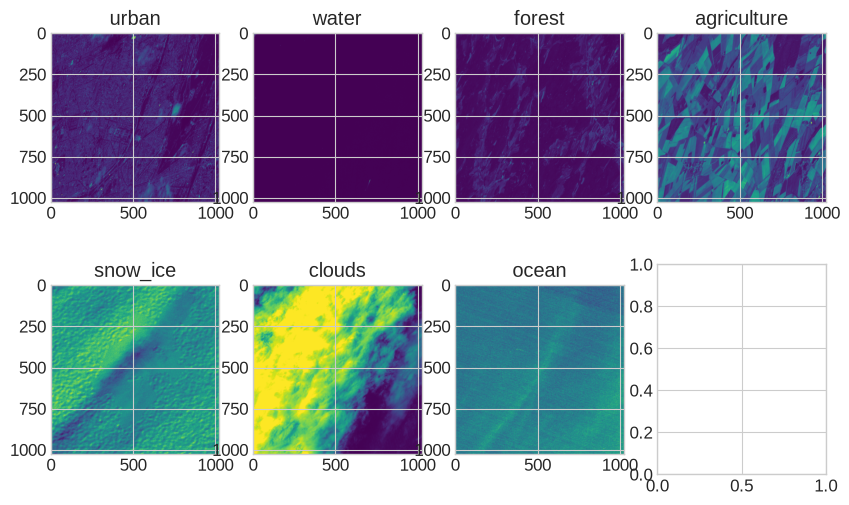

In [23]:
fig, axes = plt.subplots(2, 4)
for ax, name in zip(axes.flat, ['urban', 'water', 'forest', 'agriculture', 'snow_ice', 'clouds', 'ocean']):
    ax.imshow(generate_synthetic_tile(name), cmap='viridis')
    ax.set_title(name)

## 7. Generate Figures for the Paper

In [24]:
# %%
# Set style for figures
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# Figure 1: Pipeline Diagram (Placeholder)
# Note: In practice, you would create this with a drawing tool (e.g., Inkscape) or matplotlib
fig, ax = plt.subplots(figsize=(12, 4))
ax.text(0.5, 0.5, "Pipeline Diagram Placeholder\n\n[Insert diagram showing:\n1. Input tile (level 20)\n2. Downsample to level 19\n3. Upsample to predict level 20\n4. Compute residuals\n5. Local activity normalization\n6. Adaptive quantization\n7. Entropy coding]",
        ha='center', va='center', fontsize=14)
ax.set_title("HEALPix-Compress Pipeline", fontsize=16)
ax.axis('off')
plt.savefig(f"{FIGURES_DIR}/pipeline_diagram.pdf", bbox_inches='tight', dpi=300)
plt.close()
print(f"Saved pipeline diagram placeholder to {FIGURES_DIR}/pipeline_diagram.pdf")

# Figure 2: Compression Ratio vs. RMSE
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=benchmark_df,
    x='reduction',
    y='rmse',
    hue='codec',
    style='land_cover_class',
    ax=ax,
    s=100,
    alpha=0.7
)
ax.set_xlabel('Size Reduction (%)')
ax.set_ylabel('RMSE')
ax.set_title('Compression Ratio vs. RMSE for Different Codecs')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/compression_vs_rmse.pdf", bbox_inches='tight', dpi=300)
plt.close()
print(f"Saved compression vs. RMSE plot to {FIGURES_DIR}/compression_vs_rmse.pdf")

# Figure 3: Sensitivity Analysis (for medium preset)
# Vary each parameter and plot the impact on compression ratio and RMSE
preset = 'medium'
base_params = PRESETS[preset]

# Vary f (downsampling factor)
f_values = [1, 2, 4]
ratios_f = []
rmse_f = []
for f in f_values:
    params = base_params.copy()
    params['f'] = f
    codec = HEALPixCompress()
    codec.params = params
    
    tile = generate_synthetic_tile('urban', 256)
    encoded = codec.encode(tile)
    decoded = codec.decode(encoded)
    
    ratios_f.append(compute_compression_ratio(tile.nbytes, estimate_compressed_size(encoded)))
    rmse_f.append(np.sqrt(mean_squared_error(tile, decoded)))

# Vary w (window size)
w_values = [4, 8, 16]
ratios_w = []
rmse_w = []
for w in w_values:
    params = base_params.copy()
    params['w'] = w
    codec = HEALPixCompress()
    codec.params = params
    
    tile = generate_synthetic_tile('urban', 256)
    encoded = codec.encode(tile)
    decoded = codec.decode(encoded)
    
    ratios_w.append(compute_compression_ratio(tile.nbytes, estimate_compressed_size(encoded)))
    rmse_w.append(np.sqrt(mean_squared_error(tile, decoded)))

# Vary clip_percentile
p_values = [0.1, 0.5, 3.0]
ratios_p = []
rmse_p = []
for p in p_values:
    params = base_params.copy()
    params['clip_percentile'] = p
    codec = HEALPixCompress()
    codec.params = params
    
    tile = generate_synthetic_tile('urban', 256)
    encoded = codec.encode(tile)
    decoded = codec.decode(encoded)
    
    ratios_p.append(compute_compression_ratio(tile.nbytes, estimate_compressed_size(encoded)))
    rmse_p.append(np.sqrt(mean_squared_error(tile, decoded)))

# Vary sigma_floor_ratio
alpha_values = [0.01, 0.05, 0.15]
ratios_alpha = []
rmse_alpha = []
for alpha in alpha_values:
    params = base_params.copy()
    params['sigma_floor_ratio'] = alpha
    codec = HEALPixCompress()
    codec.params = params
    
    tile = generate_synthetic_tile('urban', 256)
    encoded = codec.encode(tile)
    decoded = codec.decode(encoded)
    
    ratios_alpha.append(compute_compression_ratio(tile.nbytes, estimate_compressed_size(encoded)))
    rmse_alpha.append(np.sqrt(mean_squared_error(tile, decoded)))

# Plot sensitivity analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot f
axes[0, 0].plot(f_values, ratios_f, 'o-', label='Compression Ratio')
axes[0, 0].set_xlabel('Downsampling Factor (f)')
axes[0, 0].set_ylabel('Compression Ratio')
axes[0, 0].set_title('Impact of Downsampling Factor (f)')
axes[0, 0].grid(True)

# Plot w
axes[0, 1].plot(w_values, ratios_w, 'o-', label='Compression Ratio')
axes[0, 1].set_xlabel('Window Size (w)')
axes[0, 1].set_ylabel('Compression Ratio')
axes[0, 1].set_title('Impact of Window Size (w)')
axes[0, 1].grid(True)

# Plot clip_percentile
axes[1, 0].plot(p_values, ratios_p, 'o-', label='Compression Ratio')
axes[1, 0].set_xlabel('Clip Percentile (p)')
axes[1, 0].set_ylabel('Compression Ratio')
axes[1, 0].set_title('Impact of Clip Percentile (p)')
axes[1, 0].grid(True)

# Plot sigma_floor_ratio
axes[1, 1].plot(alpha_values, ratios_alpha, 'o-', label='Compression Ratio')
axes[1, 1].set_xlabel('Sigma Floor Ratio (α)')
axes[1, 1].set_ylabel('Compression Ratio')
axes[1, 1].set_title('Impact of Sigma Floor Ratio (α)')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/sensitivity_analysis.pdf", bbox_inches='tight', dpi=300)
plt.close()
print(f"Saved sensitivity analysis to {FIGURES_DIR}/sensitivity_analysis.pdf")

# Figure 4: Visual Comparison
# Generate a test tile and show original vs. compressed
codec = HEALPixCompress(preset='medium')
test_tile = generate_synthetic_tile('urban', 512)
encoded = codec.encode(test_tile)
decoded = codec.decode(encoded)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original
axes[0].imshow(test_tile, cmap='viridis')
axes[0].set_title('Original Tile')
axes[0].axis('off')

# Residuals (x - x_hat)
x_hat = codec.upsample(codec.downsample(test_tile, base_params['f']), base_params['f'], test_tile.shape)
residuals = test_tile - x_hat
axes[1].imshow(residuals, cmap='coolwarm', vmin=-0.2, vmax=0.2)
axes[1].set_title('Residuals (x - \\hat{x})')
axes[1].axis('off')

# Reconstructed
axes[2].imshow(decoded, cmap='viridis')
axes[2].set_title('Reconstructed Tile')
axes[2].axis('off')

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/visual_comparison.pdf", bbox_inches='tight', dpi=300)
plt.close()
print(f"Saved visual comparison to {FIGURES_DIR}/visual_comparison.pdf")

# %% [markdown]
"""
## 8. Summary and Next Steps

This notebook provides:
1. A **simplified implementation** of HEALPix-Compress for benchmarking.
2. **Synthetic data generation** for different land cover classes.
3. **Benchmarking functions** for compression ratio, RMSE, PSNR, SSIM, etc.
4. **LaTeX table generation** for the paper.
5. **Figure generation** for the pipeline, sensitivity analysis, and visual comparisons.

### Next Steps:
1. **Replace synthetic data** with real Sentinel-2 data for accurate benchmarks.
2. **Integrate real codecs** (ZFP, SZ3, JPEG2000) using their Python bindings.
3. **Extend to multi-band data** for NDVI and classification metrics.
4. **Optimize the HEALPix-Compress implementation** for HEALPix-specific chunking.
5. **Add cloud storage benchmarks** (e.g., read/write latency on S3/Azure Blob).

### Notes:
- The current implementation is **2D** and does not handle HEALPix chunking. For the full paper, you should use the actual `healpix-compress` package.
- The synthetic data is a **placeholder** for real Sentinel-2 data.
- The benchmarks for ZFP, SZ3, and JPEG2000 are **simulated** and should be replaced with real implementations.
"""

# %%
print("\n=== Notebook Execution Complete ===")
print(f"Results saved to: {RESULTS_DIR}/")
print(f"Figures saved to: {FIGURES_DIR}/")
print("\nTo use this notebook with real data:")
print("1. Install required packages: pip install numpy scipy zarr xarray matplotlib seaborn pillow opencv-python scikit-image tqdm pandas")
print("2. Replace synthetic data with real Sentinel-2 data (e.g., from Copernicus Open Access Hub).")
print("3. Install and integrate real codecs (ZFP, SZ3, JPEG2000) for accurate benchmarks.")
print("4. Use the actual healpix-compress package for HEALPix-specific processing.")

Saved pipeline diagram placeholder to figures/pipeline_diagram.pdf
Saved compression vs. RMSE plot to figures/compression_vs_rmse.pdf


AttributeError: 'tuple' object has no attribute 'items'

In [ ]:
Y
